# 09 — Campagnes de phishing avec K-Means

**Objectif** : regrouper sans supervision les URL de phishing d'une même famille d'attaque (même kit, même technique). Pour un SOC : « 1 campagne, 50 URL » plutôt que 50 alertes isolées.

**Données** : les 4 432 URL de phishing du **train**, 79 colonnes du modèle principal (lues dans `models/thresholds.json`), normalisées (`StandardScaler`, indispensable : K-Means calcule des distances).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 1. Préparation

In [2]:
train = pd.read_csv("../data/processed/train.csv")
COLS = json.load(open("../models/thresholds.json"))["url_content"]["columns"]

phish = train[train["status"] == "phishing"].reset_index(drop=True)
Xp = StandardScaler().fit_transform(phish[COLS])

ks = range(2, 13)
inertia, silhouette = [], []

## 2. Choix de k : coude et silhouette

- **Coude** : l'inertie baisse toujours quand k augmente ; on cherche où elle baisse nettement moins vite.
- **Silhouette** (−1 à 1) : chaque URL est-elle plus proche de son groupe que du groupe voisin ?

In [3]:
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xp)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Xp, km.labels_))

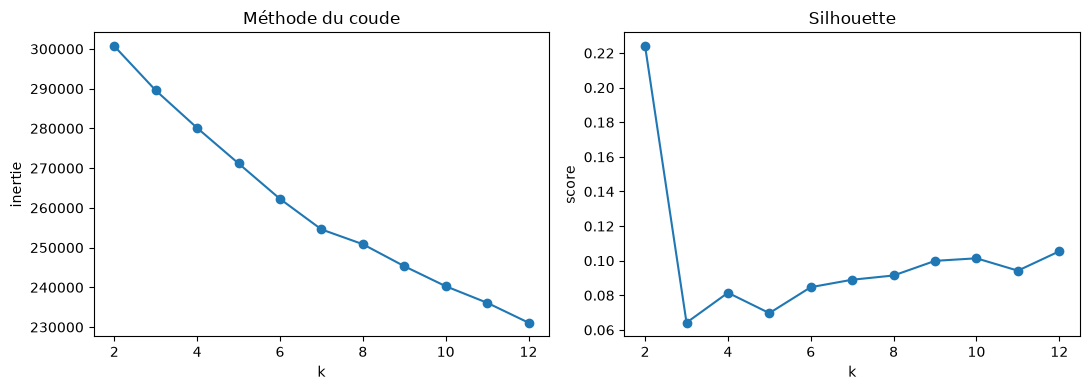

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Méthode du coude", xlabel="k", ylabel="inertie")
ax[1].plot(ks, silhouette, "o-"); ax[1].set(title="Silhouette", xlabel="k", ylabel="score")
plt.tight_layout(); plt.show()

**Lecture** : aucun coude net ; silhouette très basse (0,22 à k = 2, puis 0,06–0,10) → le phishing ne forme pas de groupes bien **séparés**. Piège : k = 2 a la meilleure silhouette mais sépare seulement les URL longues à paramètres des autres (une forme d'URL, pas une campagne).

## 3. Validation par les campagnes connues

La silhouette ne suffit pas. Les gros sites de phishing (colonne `group`, **non utilisée** par K-Means) sont des campagnes connues : un bon clustering doit les garder ensemble. **Pureté** = part des URL d'un site (≥ 10 URL) qui tombent dans un même cluster.

In [5]:
def campaign_purity(labels, min_size=10):
    """Pour chaque site de phishing avec au moins min_size URL :
    part de ses URL qui tombent dans le même cluster."""
    df = pd.DataFrame({"group": phish["group"], "cluster": labels})
    sizes = df["group"].value_counts()
    big = sizes[sizes >= min_size].index
    return (df[df["group"].isin(big)]
            .groupby("group")["cluster"]
            .agg(lambda s: s.value_counts(normalize=True).iloc[0]))

In [6]:
rows = []
for k in [2, 4, 6, 8, 10]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xp)
    purity = campaign_purity(labels)
    rows.append({"k": k, "silhouette": round(silhouette_score(Xp, labels), 3),
                 "pureté moyenne": round(purity.mean(), 3), "campagnes vérifiées": len(purity),
                 "tailles des clusters": sorted(np.bincount(labels).tolist(), reverse=True)})
pd.DataFrame(rows)

,k,silhouette,pureté moyenne,campagnes vérifiées,tailles des clusters
0,2,0.224,0.948,20,"[3486, 946]"
1,4,0.081,0.879,20,"[2332, 1181, 491, 428]"
2,6,0.085,0.852,20,"[1547, 1092, 913, 423, 389, 68]"
3,8,0.091,0.844,20,"[1466, 921, 874, 427, 376, 228, 78, 62]"
4,10,0.101,0.811,20,"[1481, 918, 871, 366, 295, 228, 101, 100, 57, 15]"


**Résultat** :

| k | Silhouette | Pureté moyenne | Plus petit cluster |
| --- | --- | --- | --- |
| 2 | 0,224 | 0,948 | 946 |
| 4 | 0,081 | 0,879 | 428 |
| 6 | 0,085 | 0,852 | 68 |
| **8** | 0,091 | **0,844** | 62 |
| 10 | 0,101 | 0,811 | 15 |

**Choix : k = 8** : pureté presque égale à k = 6 avec des groupes plus fins ; à k = 10 la pureté baisse et un cluster de 15 URL apparaît. Les 331 URL de `duilawyeryork.com` tombent toutes dans le même cluster.

## 4. Description des 8 clusters

Centres en écarts-types par rapport à la moyenne du phishing : les 4 valeurs les plus éloignées de 0 définissent le cluster.

In [7]:
K = 8
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xp)
phish["cluster"] = km.labels_
centers = pd.DataFrame(km.cluster_centers_, columns=COLS)

for c in centers.index:
    part = phish[phish["cluster"] == c]
    top = centers.loc[c].abs().sort_values(ascending=False).head(4).index
    print(f"=== Cluster {c} : {len(part)} URL")
    print("  caractéristiques marquantes :", ", ".join(f"{f} ({centers.loc[c, f]:+.1f})" for f in top))
    print("  sites principaux :", part["group"].value_counts().head(3).to_dict())
    for u in part["url"].sample(min(3, len(part)), random_state=42):
        print("     ", u[:90])
    print()


=== Cluster 0 : 376 URL
  caractéristiques marquantes : tld_in_subdomain (+2.6), length_hostname (+1.9), nb_com (+1.6), safe_anchor (+1.5)
  sites principaux : {'duilawyeryork.com': 331, 'clearpointsupplies.com': 5, 'illmickelsonbeats.com': 3}
      http://support-appleld.com.secureupdate.duilawyeryork.com/ap/4abbb85f1fc9deb/?cmd=_update&
      https://support-appleld.com.secureupdate.duilawyeryork.com/ap/9f1dc61cd47566e?cmd=_update&
      http://secureupdate.appleld.com.duilawyeryork.com/ap/031ef937ed415a4/?cmd=_update&dispatch

=== Cluster 1 : 921 URL
  caractéristiques marquantes : ratio_extHyperlinks (+1.4), external_favicon (+1.1), ratio_extMedia (+0.9), domain_in_brand (+0.9)
  sites principaux : {'google.com': 110, 'myfreesites.net': 19, 'my-free.website': 16}
      http://makrobettgir1.blogspot.com
      http://outlook-webapp-portal.el.r.appspot.com/linkedrecruiter.html
      https://mailgcccdeduowa.my-free.website/

=== Cluster 2 : 874 URL
  caractéristiques marquantes : empty

In [8]:
CLUSTER_NAMES = {
    0: "Faux sous-domaines de marque",
    1: "Plateformes gratuites détournées",
    2: "Pages minimalistes sans titre",
    3: "URL à paramètres / redirecteurs",
    4: "Vol d'identifiants",
    5: "Hébergement sur adresse IP",
    6: "Sites compromis (WordPress)",
    7: "Jetons encodés / proxys",
}
phish["campagne"] = phish["cluster"].map(CLUSTER_NAMES)
phish["campagne"].value_counts()


campagne
Sites compromis (WordPress)         1466
Plateformes gratuites détournées     921
Pages minimalistes sans titre        874
URL à paramètres / redirecteurs      427
Faux sous-domaines de marque         376
Vol d'identifiants                   228
Hébergement sur adresse IP            78
Jetons encodés / proxys               62
Name: count, dtype: int64

**Les 8 familles d'attaque** :

| # | URL | Ce qui le définit | Exemple | Nom |
| --- | --- | --- | --- | --- |
| 0 | 376 | TLD dans le sous-domaine | `support-appleld.com.secureupdate.duilawyeryork.com` | Faux sous-domaines de marque |
| 1 | 921 | Liens et favicon externes | `google.com`, `blogspot`, `my-free.website` | Plateformes gratuites détournées |
| 2 | 874 | Titre vide, peu de liens internes | `firebaseapp.com`, dossiers cachés | Pages minimalistes sans titre |
| 3 | 427 | URL longues, nombreux `=` et `?` | `index.php?email=…`, redirecteurs | URL à paramètres / redirecteurs |
| 4 | 228 | Formulaire de connexion | `justlookapp.com` | Vol d'identifiants |
| 5 | 78 | Chiffres dans l'hôte, IP | `http://216.83.55.154/…` | Hébergement sur adresse IP |
| 6 | 1 466 | Liens internes (gabarit du site hôte) | `wp-content/`, `wp-includes/` | Sites compromis (WordPress) |
| 7 | 62 | Mots très longs | `…/direct/aHR0cHM6Ly…` (base64 de `https://`) | Jetons encodés / proxys |

## 5. Sauvegarde du modèle de campagnes

Normalisation + K-Means dans un seul `Pipeline`, avec les noms des clusters ; l'`assert` vérifie que la numérotation est identique à celle qu'on a nommée.

In [9]:
import joblib
from sklearn.pipeline import make_pipeline

In [10]:
campaign_model = make_pipeline(StandardScaler(),KMeans(n_clusters=8, n_init=10, random_state=42)).fit(phish[COLS])

In [11]:
# Vérification : même découpage que les clusters qu'on vient de nommer
assert (campaign_model[-1].labels_ == phish["cluster"].values).all()

In [12]:
joblib.dump({"model": campaign_model, "names": CLUSTER_NAMES, "columns": COLS},
            "../models/kmeans_campaigns.joblib", compress=3)
print("sauvegardé")

sauvegardé


## Conclusion

- Silhouette basse mais **pureté haute** : les clusters ne sont pas bien séparés entre eux, mais ils sont **cohérents** à l'intérieur ; un cluster correspond plutôt à une **famille de techniques** qu'à une campagne unique.
- Les 8 familles sont reconnaissables par un analyste (faux sous-domaines, sites WordPress compromis, IP, redirecteurs…) et orientent la réponse (ex. prévenir le propriétaire d'un site compromis plutôt que bloquer tout le domaine).
- Modèle enregistré : `models/kmeans_campaigns.joblib`, utilisé par l'interface (« famille d'attaque la plus proche »).